# Approaches

Before building the pipeline, compare the different ways captions could be produced. A few are prototyped quickly on real data, the rest are discussed. Goal is to pick one approach and know why.

A good caption here has three parts: the occasion, place and date. E.g. "Beach day in Brighton, July 2023". Each part can come from a different source, and each source has different strengths.

In [14]:
import contextlib
import io
import json
import random
import re
from collections import Counter
from datetime import datetime
from pathlib import Path

import pandas as pd
import pycountry
import reverse_geocoder as rg
from PIL import Image

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = ROOT / "data"
FOLDERS = sorted(p.name for p in DATA.iterdir() if p.is_dir())

## Shared helpers

Same loading logic as first notebook, kept short. These move into the `captioner` package later.

In [15]:
KEY_RE = re.compile(r"([{,\[]\s*)([A-Za-z_][A-Za-z0-9_]*)\s*:")


def parse_labels(path: Path) -> list[dict]:
    return json.loads(KEY_RE.sub(r'\1"\2":', path.read_text()))["Labels"]


def to_degrees(dms, ref) -> float:
    d = float(dms[0]) + float(dms[1]) / 60 + float(dms[2]) / 3600
    return -d if ref in ("S", "W") else d


def read_exif(path: Path) -> dict:
    with Image.open(path) as im:
        exif = im.getexif()
    raw = exif.get_ifd(0x8769).get(36867) or exif.get(306)
    gps = exif.get_ifd(0x8825)
    ok = 2 in gps and 4 in gps
    return {
        "taken_at": datetime.strptime(raw, "%Y:%m:%d %H:%M:%S") if raw else None,
        "lat": to_degrees(gps[2], gps.get(1, "N")) if ok else None,
        "lon": to_degrees(gps[4], gps.get(3, "E")) if ok else None,
    }


rows = []
for folder in FOLDERS:
    for img in sorted((DATA / folder).glob("*.jpg")):
        labs = parse_labels(img.with_name(img.name + ".json"))
        rows.append(
            {
                "folder": folder,
                "file": img.name,
                **read_exif(img),
                "labels": {lab["Name"]: lab["Confidence"] / 100 for lab in labs},
            }
        )

photos = pd.DataFrame(rows)
print(f"{len(photos)} photos")

313 photos


In [16]:
with contextlib.redirect_stdout(io.StringIO()):
    geocoder = rg.RGeocoder(mode=1, verbose=False)


def place_name(lat: float, lon: float, home: str = "GB") -> str:
    """Town at home, town plus country abroad."""
    hit = geocoder.query([(lat, lon)])[0]
    if hit["cc"] == home:
        return hit["name"]
    country = pycountry.countries.get(alpha_2=hit["cc"])
    return f"{hit['name']}, {getattr(country, 'common_name', country.name)}"


def page_date(idx: list[int]) -> str:
    ts = photos.loc[idx, "taken_at"]
    lo, hi = ts.min(), ts.max()
    if (lo.year, lo.month) == (hi.year, hi.month):
        return f"{lo:%B %Y}"
    if lo.year == hi.year:
        return f"{lo:%b}–{hi:%b %Y}"
    return f"{lo.year}–{hi.year}"


def page_place(idx: list[int]) -> str:
    r = photos.loc[idx[0]]
    return place_name(r.lat, r.lon)

## Test pages

100 random pages per folder for each page size (1, 2 and 3 photos), so 1,200 pages. Seeded so results repeat. Random sampling is optimistic but fine for comparing approaches against each other.

In [17]:
rng = random.Random(0)
pages = []
for folder in FOLDERS:
    idx = photos.index[photos.folder == folder].tolist()
    for k in (1, 2, 3):
        for _ in range(100):
            pages.append({"folder": folder, "k": k, "idx": rng.sample(idx, k)})

pages = pd.DataFrame(pages)
pages.groupby(["folder", "k"]).size().unstack()

k,1,2,3
folder,,,
day-at-beach,100,100,100
garden-birthday-party,100,100,100
skiing-holiday,100,100,100
summer-with-grandkids,100,100,100


## 1. Options

Six broad approaches:

- A. Raw labels as caption. Join the top Rekognition labels. Simplest possible baseline.
- B. Metadata only. Place and date from EXIF, nothing about the scene.
- C. Facts first, then template. Map labels onto a small set of occasions, combine with place and date from EXIF, fill a template.
- D. Vision-language model on the pixels. Send photos to a hosted model (GPT-4o, Claude, Gemini) or a self-hosted one (BLIP-2, Florence-2, Qwen-VL) and ask for a caption.
- E. Zero-shot image-text matching (CLIP). Score each photo against text prompts such as "a photo of a beach day" and pick the best occasion. Small enough to run on a phone.
- F. Facts first, then LLM writer. Same facts as C, but a small language model writes the final wording. Model sees only text facts, never the photos.

A, B and C are cheap to try on this data, hence prototyped below. D, E and F are discussed after.

## 2. Raw labels as caption (A)

Sum label confidence across photos on the page and take the top three. Second version drops generic people and clothing labels.

In [18]:
GENERIC = {
    "Person",
    "Human",
    "People",
    "Apparel",
    "Clothing",
    "Face",
    "Photo",
    "Photography",
    "Portrait",
    "Female",
    "Male",
    "Girl",
    "Boy",
    "Woman",
    "Man",
}


def caption_raw_labels(idx: list[int], n: int = 3, skip: set[str] = frozenset()) -> str:
    score = Counter()
    for i in idx:
        for name, conf in photos.at[i, "labels"].items():
            if name not in skip:
                score[name] += conf
    return ", ".join(name for name, _ in score.most_common(n))


pages["raw_labels"] = pages.idx.map(caption_raw_labels)
pages["raw_labels_filtered"] = pages.idx.map(lambda i: caption_raw_labels(i, skip=GENERIC))

pages[pages.k == 2].groupby("folder").head(3)[["folder", "raw_labels", "raw_labels_filtered"]]

,folder,raw_labels,raw_labels_filtered
100,day-at-beach,"Person, Human, Vacation","Vacation, Family, Water"
101,day-at-beach,"Human, Person, Outdoors","Outdoors, Nature, Sports"
102,day-at-beach,"Human, Person, People","Family, Sport, Sports"
400,garden-birthday-party,"Clothing, Apparel, Hat","Hat, Party Hat, Dessert"
401,garden-birthday-party,"Clothing, Apparel, Hat","Hat, Party Hat, Birthday Party"
402,garden-birthday-party,"Apparel, Clothing, Person","Hat, Party Hat, Birthday Party"
700,skiing-holiday,"Person, Human, Clothing","Nature, Outdoors, Crowd"
701,skiing-holiday,"Face, Person, Human","Smile, Outdoors, Nature"
702,skiing-holiday,"Human, Person, Clothing","Helmet, Nature, Outdoors"
1000,summer-with-grandkids,"Clothing, Pants, Apparel","Pants, Denim, Jeans"


### Raw labels: findings

Unfiltered, almost every caption is some mix of "Human, Person, People". Filtering helps a little, but output is still list of objects rather than a description of a moment ("Pants, Denim, Jeans", "Indoors, Couch, Furniture", "Nature, Outdoors, Crowd"). No date or place, and nothing stops implausible labels coming through. Not usable as a caption. Labels are evidence, not wording.

## 3. Metadata only (B)

Place and date from EXIF. No scene understanding at all.

In [19]:
pages["metadata_only"] = [f"{page_place(i)}, {page_date(i)}" for i in pages.idx]
pages[pages.k == 2].groupby("folder").head(1)[["folder", "metadata_only"]]

,folder,metadata_only
100,day-at-beach,"Bondi Beach, Australia, March 2018"
400,garden-birthday-party,"Catford, February 2019"
700,skiing-holiday,"Yuzawa, Japan, February 2020"
1000,summer-with-grandkids,"Knutsford, September 2018"


### Metadata only: findings

Gives "Catford, February 2019", "Yuzawa, Japan, February 2020". Always factually right as long as EXIF is right, instant, free and fully private. Already a reasonable caption for a photobook page.

But says nothing about what's happening specificially, which is what makes a caption feel personal. Relatively decent baseline and a safe fallback, however not the whole answer.

## 4. Facts first, then template (C)

Map labels onto a small set of occasions. Each occasion has a few weighted evidence labels. For a page, score each occasion per photo (sum of weight × confidence), then average the page mean and page max - one clear photo should be enough, but agreement across photos should count for more. Below a threshold no occasion is claimed, and caption falls back to place and date.

Occasion list is deliberately small here, just enough to cover the four folders. Full list comes later in the pipeline config.

In [20]:
OCCASIONS = {
    "Beach day": {
        "Beach": 3,
        "Shoreline": 2,
        "Coast": 2,
        "Sand": 2,
        "Sea": 1.5,
        "Ocean": 1.5,
        "Swimwear": 1.5,
    },
    "Birthday party": {
        "Birthday Party": 4,
        "Birthday Cake": 4,
        "Party Hat": 3,
        "Balloon": 1.5,
        "Cake": 0.7,
    },
    "Skiing": {"Skiing": 4, "Piste": 3, "Snowboarding": 3, "Slope": 1.5, "Snow": 1.5},
    "Baking": {"Baking": 4, "Cookie": 1.5, "Biscuit": 1.5, "Oven": 2, "Cooktop": 1},
}
THRESHOLD = 1.0


def occasion_scores(idx: list[int], pool: str = "page") -> dict[str, float]:
    out = {}
    for name, weights in OCCASIONS.items():
        per_photo = [
            sum(weights.get(lab, 0) * c for lab, c in photos.at[i, "labels"].items()) for i in idx
        ]
        mean = sum(per_photo) / len(per_photo)
        out[name] = mean if pool == "day" else (mean + max(per_photo)) / 2
    return out


def occasion(idx: list[int]) -> str | None:
    scores = occasion_scores(idx)
    best = max(scores, key=scores.get)
    return best if scores[best] >= THRESHOLD else None


def caption_facts(idx: list[int]) -> str:
    occ = occasion(idx)
    where, when = page_place(idx), page_date(idx)
    return f"{occ} in {where}, {when}" if occ else f"{where}, {when}"


pages["occasion"] = pages.idx.map(lambda i: occasion(i) or "(none)")
pages["facts_template"] = pages.idx.map(caption_facts)
pages[pages.k == 3].groupby("folder").head(2)[["folder", "facts_template"]]

,folder,facts_template
200,day-at-beach,"Beach day in Bondi Beach, Australia, March 2018"
201,day-at-beach,"Beach day in Bondi Beach, Australia, March 2018"
500,garden-birthday-party,"Birthday party in Catford, February 2019"
501,garden-birthday-party,"Birthday party in Catford, February 2019"
800,skiing-holiday,"Skiing in Yuzawa, Japan, February 2020"
801,skiing-holiday,"Skiing in Yuzawa, Japan, February 2020"
1100,summer-with-grandkids,"Knutsford, September 2018"
1101,summer-with-grandkids,"Knutsford, September 2018"


In [21]:
pd.crosstab([pages.folder, pages.k], pages.occasion, normalize="index").round(2)

occasion                 (none)  Baking  Beach day  Birthday party  Skiing
folder                k                                                   
day-at-beach          1    0.81    0.00       0.19            0.00    0.00
                      2    0.67    0.00       0.33            0.00    0.00
                      3    0.64    0.00       0.36            0.00    0.00
garden-birthday-party 1    0.34    0.00       0.00            0.66    0.00
                      2    0.08    0.00       0.00            0.92    0.00
                      3    0.05    0.00       0.00            0.95    0.00
skiing-holiday        1    0.33    0.00       0.04            0.00    0.63
                      2    0.23    0.00       0.01            0.00    0.76
                      3    0.11    0.00       0.03            0.00    0.86
summer-with-grandkids 1    0.83    0.17       0.00            0.00    0.00
                      2    0.52    0.48       0.00            0.00    0.00
                      3    0.38    0.62       0.00            0.00    0.00

In [22]:
EXPECTED = {
    "day-at-beach": "Beach day",
    "garden-birthday-party": "Birthday party",
    "skiing-holiday": "Skiing",
}

stock = pages[pages.folder.isin(EXPECTED)].copy()
stock["outcome"] = [
    "right" if o == EXPECTED[f] else "none" if o == "(none)" else "wrong"
    for f, o in zip(stock.folder, stock.occasion)
]
pd.crosstab([stock.folder, stock.k], stock.outcome, normalize="index").round(2)

outcome                  none  right  wrong
folder                k                    
day-at-beach          1  0.81   0.19   0.00
                      2  0.67   0.33   0.00
                      3  0.64   0.36   0.00
garden-birthday-party 1  0.34   0.66   0.00
                      2  0.08   0.92   0.00
                      3  0.05   0.95   0.00
skiing-holiday        1  0.33   0.63   0.04
                      2  0.23   0.76   0.01
                      3  0.11   0.86   0.03

In [23]:
def evidence(idx: list[int], occ: str) -> list[str]:
    return sorted({lab for i in idx for lab in photos.at[i, "labels"] if lab in OCCASIONS[occ]})


wrong = stock[stock.outcome == "wrong"].copy()
wrong["files"] = wrong.idx.map(lambda i: [photos.at[j, "file"] for j in i])
wrong["evidence"] = [evidence(i, o) for i, o in zip(wrong.idx, wrong.occasion)]
wrong[["folder", "k", "files", "occasion", "evidence"]].head(8)

,folder,k,files,occasion,evidence
604,skiing-holiday,1,[Image_66.jpg],Beach day,"[Ocean, Sea]"
656,skiing-holiday,1,[Image_49.jpg],Beach day,"[Beach, Coast, Ocean, Sea, Shoreline]"
671,skiing-holiday,1,[Image_49.jpg],Beach day,"[Beach, Coast, Ocean, Sea, Shoreline]"
698,skiing-holiday,1,[Image_49.jpg],Beach day,"[Beach, Coast, Ocean, Sea, Shoreline]"
725,skiing-holiday,2,"[Image_46.jpg, Image_49.jpg]",Beach day,"[Beach, Coast, Ocean, Sea, Shoreline]"
819,skiing-holiday,3,"[Image_49.jpg, Image_28.jpg, Image_26.jpg]",Beach day,"[Beach, Coast, Ocean, Sea, Shoreline]"
849,skiing-holiday,3,"[Image_29.jpg, Image_49.jpg, Image_64.jpg]",Beach day,"[Beach, Coast, Ocean, Sea, Shoreline]"
868,skiing-holiday,3,"[Image_28.jpg, Image_49.jpg, Image_68.jpg]",Beach day,"[Beach, Coast, Ocean, Sea, Shoreline]"


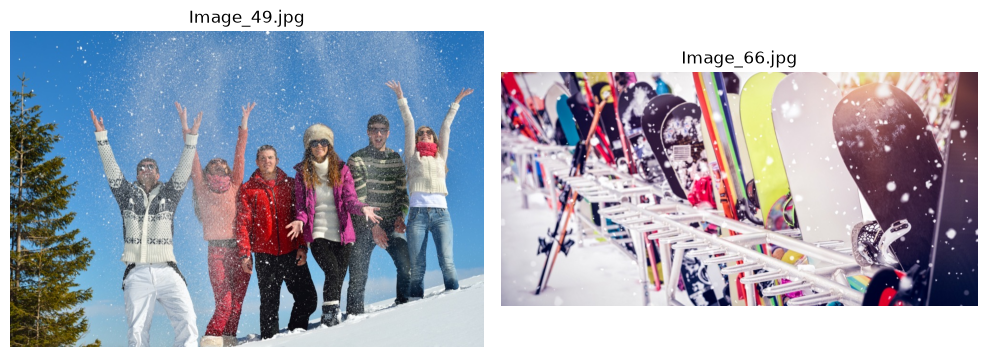

In [24]:
import matplotlib.pyplot as plt
from PIL import ImageOps

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, ["Image_49.jpg", "Image_66.jpg"]):
    with Image.open(DATA / "skiing-holiday" / name) as im:
        ax.imshow(ImageOps.exif_transpose(im))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Facts first, then template: findings

When it names an occasion, it's almost always right. No birthday party or beach page is ever mislabelled. Only wrong cases are skiing pages called "Beach day", and nearly all come from two photos:

- Image_49 - group throwing snow on a slope under blue sky. Rekognition labels it Beach, Coast, Shoreline, Sea and Ocean, but also Snow (93%), Winter and Ice.
- Image_66 - rack of snowboards. Gets Sea and Ocean, probably from blue board graphics, alongside Shop, Market and Bazaar. No Snow label.

Main weakness is abstaining, not being wrong. With one photo, beach pages get an occasion only 19% of the time, garden party 66%, skiing 63%. With three photos this rises to 36%, 95% and 86%. Beach stays hard because most photos are portraits against sky (notebook 01, section 7).

Three issues to fix in the pipeline:

- Negative evidence. Snow, Winter or Piste on the page should rule out Beach day. Fixes Image_49.
- Core labels. Beach day should need at least one of Beach, Shoreline, Sand or Coast, not just Sea and Ocean. Fixes Image_66.
- "Beach day in Bondi Beach, Australia" repeats itself. Place wording should avoid echoing the occasion.

Still a safe failure mode. Abstaining gives "Bondi Beach, Australia, March 2018", which is a decent caption. Confidently wrong would be much worse.

## 5. Adding photos from the same day

Single photos often carry no evidence, but the rest of that day usually does. Quick test: if the page alone can't decide, look at all other photos taken within 36 hours, average their scores (plain mean, lower threshold since it's diluted over many photos), and use that occasion if it's clear.

In [25]:
DAY_THRESHOLD = 0.4
DAY_MARGIN = 0.2


def same_day(idx: list[int]) -> list[int]:
    first = photos.loc[idx[0]]
    near = photos[(photos.taken_at - first.taken_at).abs() <= pd.Timedelta(hours=36)]
    return [i for i in near.index if i not in idx]


def occasion_with_context(idx: list[int]) -> str | None:
    page = occasion(idx)
    if page:
        return page
    day = sorted(
        occasion_scores(same_day(idx), pool="day").items(), key=lambda kv: kv[1], reverse=True
    )
    (best, s1), (_, s2) = day[0], day[1]
    return best if s1 >= DAY_THRESHOLD and s1 - s2 >= DAY_MARGIN else None


pages["occasion_ctx"] = pages.idx.map(lambda i: occasion_with_context(i) or "(none)")

stock = pages[pages.folder.isin(EXPECTED)].copy()
stock["page_only"] = [o == EXPECTED[f] for f, o in zip(stock.folder, stock.occasion)]
stock["with_same_day"] = [o == EXPECTED[f] for f, o in zip(stock.folder, stock.occasion_ctx)]
stock.groupby(["folder", "k"])[["page_only", "with_same_day"]].mean().round(2)

page_only  with_same_day
folder                k                          
day-at-beach          1       0.19           1.00
                      2       0.33           1.00
                      3       0.36           1.00
garden-birthday-party 1       0.66           0.98
                      2       0.92           0.99
                      3       0.95           1.00
skiing-holiday        1       0.63           0.96
                      2       0.76           0.99
                      3       0.86           0.97

In [26]:
grandkids = pages[pages.folder == "summer-with-grandkids"]
pd.crosstab(grandkids.k, [grandkids.occasion, grandkids.occasion_ctx], normalize="index").round(2)

occasion,(none),Baking
occasion_ctx,Baking,Baking
k,,
1,0.83,0.17
2,0.52,0.48
3,0.38,0.62


### Same-day context: findings

For stock folders, context fixes almost everything. Beach single photo pages go from 19% to 100% right, garden party from 66% to 98%, skiing from 63% to 96%.

Grandkids folder shows the risk though. Without context, pages showing biscuits get "Baking" and the rest get no occasion. With context, every page becomes "Baking", including photos on the sofa or in the garden. A real day has several activities, and borrowing the day's main one over-generalises.

Test is also optimistic. Each folder is effectively one pre-grouped occasion, so "same day" is clean here. In a real library a 36-hour window would mix unrelated things.

Context is worth using, but carefully:

- Tighter window, e.g. the same session or "moment" the curation step already builds, not a whole day.
- Only borrow an occasion when the page has no evidence against it (an indoor page shouldn't inherit "Beach day").
- Softer wording when the occasion is borrowed rather than seen on the page.

Evaluation needs to measure both sides - how much context helps the stock folders, and how often it over generalises on the grandkids folder.

## 6. Approaches not prototyped here

### D. Vision-language model on the pixels

Send the photos to a multimodal model and ask for a caption. Hosted options (GPT-4o, Claude, Gemini) give the most fluent, specific captions and need no label mapping. Self-hosted open models (BLIP-2, Florence-2, Qwen-VL, LLaVA) do the same within the company's own infrastructure.

Downsides:

- Privacy. Hosted models mean user photos leave the company's infrastructure, which production rules out. Self-hosting fixes that, but photos still leave the device.
- Invented facts. Pixels carry no date or place, so the model guesses ("Summer in Cornwall"). Wrong dates and places are the worst kind of error for a keepsake.
- Cost and latency. Roughly a second or more per page and a real per-call cost at photobook scale. Self-hosting needs GPUs.
- Harder to evaluate and control. Free text is hard to check, and style drifts between model versions.

Dates and places could still be supplied from EXIF in the prompt, which makes D more like F with pixels added. Worth revisiting as an upgrade for the "what" part once a private, self-hosted model is in place.

### E. Zero-shot image-text matching (CLIP)

Embed each photo and a set of occasion prompts ("a photo of a birthday party"), pick the closest. Works on pixels directly, so it can see the beach behind a portrait even when no "Beach" label fires. Small variants (MobileCLIP and similar) run on a phone in tens of milliseconds, so photos never leave the device. Occasion list is just text, hence easy to extend.

Downsides - scores are poorly calibrated across prompts, needs a curated prompt set and a threshold per occasion, and quality depends on prompt wording. A natural replacement for the label-mapping step of C rather than a whole approach on its own. Also useful for evaluation, as image-text similarity between photos and the finished caption.

### F. Facts first, then LLM writer

Same facts as C (occasion, place, date, plus details such as kids or garden), then a small language model turns them into a natural caption, e.g. "Baking with the kids, September 2018" instead of "Baking in Knutsford, September 2018". Model sees only a short text record, never photos.

Much nicer wording and variety across a book, while facts stay grounded. Every output can be checked automatically - any date, place or name not in the facts means the caption is rejected and the template is used instead. Text-only calls are cheap and fast, and a small model (a few billion parameters) can run on company servers or eventually on device.

Downsides - adds a model to run and monitor, small risk of odd phrasing, and the validator needs to be strict.

## 7. Comparison

Factual accuracy (date and place). B, C and F take these straight from EXIF, so they're as good as the metadata. D has to guess them unless given them. A doesn't include them.

Understanding the occasion. D strongest, E next, then C, which is limited by label quality and the occasion list. A and B have none. C fails by abstaining rather than being wrong, which is the safe direction.

Wording quality. D and F read naturally. C reads like a template - fine, but repetitive across a book.

Privacy. B, C, E and F can run with photos never leaving the device. In F only a small text record leaves it, and only if the writer is server-side. D needs photos on a server, which hosted APIs rule out.

Latency and cost. B and C effectively free and instant. E is milliseconds on device. F is a cheap text-only call or a small local model. D slowest and most expensive per page.

Control and evaluation. C fully transparent - every caption traces back to the labels that voted for it. F keeps this, plus a validator. D hardest to check or constrain.

Running offline on a phone. C works today, with on-device labels (Apple Vision, Android ML Kit) replacing Rekognition. E works today. F works with a small on-device model. D doesn't, at useful quality.

## 8. Choice

Facts first, with a template writer and an optional LLM writer on top (C + F).

1. Extract facts. Date range and place from EXIF, place via offline geocoding. Occasion from labels via a small weighted occasion list, pooled across photos on the page, with careful use of same-session photos. Simple consistency checks (season vs scene).
2. Write the caption. Template by default - always available, instant. Optional LLM writer, text only, rewrites the facts into nicer wording.
3. Validate. Any caption mentioning a date, place or name not in the facts is rejected and the template is used.

Fixes carried into the pipeline from section 4 - negative evidence (Snow rules out Beach day), core labels required per occasion, and place wording that doesn't echo the occasion.

Why this one:

- Gets the parts people care about most, when and where, right by construction.
- Fails safe. No occasion means a plain place-and-date caption, not a wrong one.
- Fits the privacy constraint. Everything up to the writer runs on device, and the writer only ever sees a few words of text.
- Cheap and fast enough to caption every page of every book.
- Easy to evaluate, since facts and wording are separate and can be checked separately.
- Clear upgrade path for each part. CLIP (E) can replace the label mapping, and a private vision model (D) can come in later for richer detail.

The pipeline itself lives in the `captioner` package (`src/captioner`), which provides `generate_caption`. Third notebook runs it on all four folders and evaluates the results.